In [4]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Plot styling — one place, applies to all charts
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("Set2")

# Default figure settings
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.titlepad'] = 15

import warnings
warnings.filterwarnings('ignore')

# Load featured dataset
df = pd.read_csv('../data/cleaned/cleaned_aqi_featured.csv', parse_dates=['Date'])

print(f"Loaded: {df.shape}")
print(f"Cities: {df['City'].nunique()} | Years: {sorted(df['Year'].unique())}")

Loaded: (24850, 21)
Cities: 26 | Years: [np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020)]


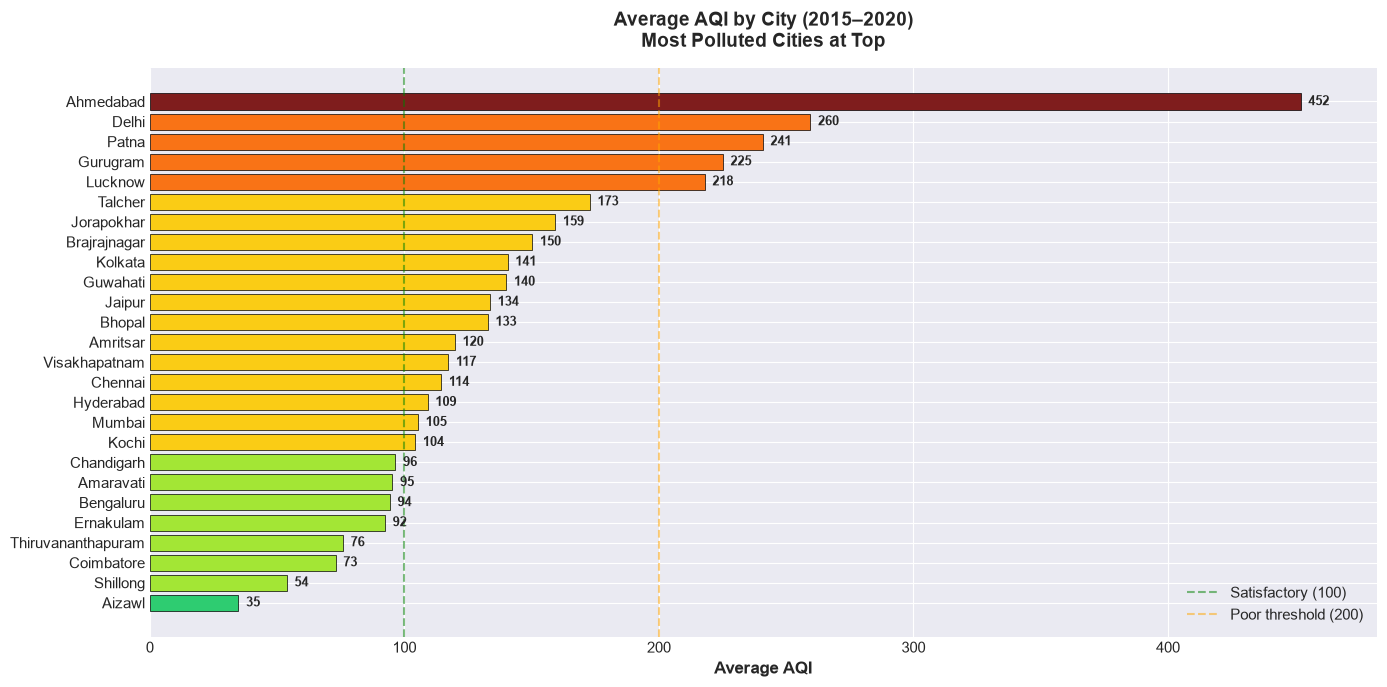


Top 5 Most Polluted Cities:
City
Ahmedabad    452.1
Delhi        259.5
Patna        240.8
Gurugram     225.1
Lucknow      218.0
Name: AQI, dtype: float64


In [5]:
# Aggregate: average AQI per city, sorted descending
city_avg = df.groupby('City')['AQI'].mean().sort_values(ascending=False).round(1)

# Color-code by AQI severity (helps visual storytelling)
def aqi_color(aqi):
    if aqi <= 50:   return '#2ecc71'   # Good      – green
    elif aqi <= 100: return '#a3e635'  # Satisfactory – light green
    elif aqi <= 200: return '#facc15'  # Moderate  – yellow
    elif aqi <= 300: return '#f97316'  # Poor      – orange
    elif aqi <= 400: return '#ef4444'  # Very Poor – red
    else:            return '#7f1d1d'  # Severe    – dark red

colors = [aqi_color(v) for v in city_avg.values]

# Plot
fig, ax = plt.subplots(figsize=(14, 7))
bars = ax.barh(city_avg.index, city_avg.values, color=colors, edgecolor='black', linewidth=0.5)

# Add value labels at the end of each bar
for bar, val in zip(bars, city_avg.values):
    ax.text(val + 3, bar.get_y() + bar.get_height()/2, f'{val:.0f}',
            va='center', fontsize=9, fontweight='bold')

# Reference lines at CPCB thresholds
ax.axvline(100, color='green', linestyle='--', alpha=0.5, label='Satisfactory (100)')
ax.axvline(200, color='orange', linestyle='--', alpha=0.5, label='Poor threshold (200)')

ax.invert_yaxis()  # Most polluted at top
ax.set_xlabel('Average AQI', fontsize=12, fontweight='bold')
ax.set_title('Average AQI by City (2015–2020)\nMost Polluted Cities at Top', fontsize=14)
ax.legend(loc='lower right')
ax.set_xlim(0, city_avg.max() + 30)

plt.tight_layout()
plt.savefig('../charts/01_city_avg_aqi.png', dpi=300, bbox_inches='tight')
plt.show()

# Print top 5 for reference
print("\nTop 5 Most Polluted Cities:")
print(city_avg.head())

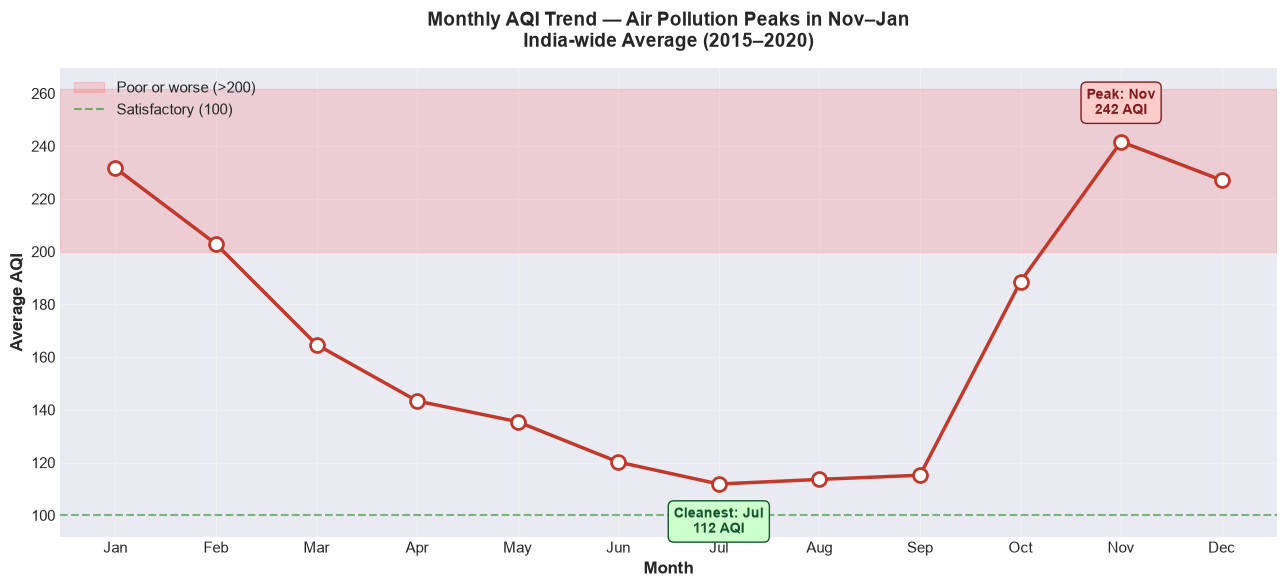

In [6]:
# Aggregate by month (keep Month numeric for correct sorting)
monthly = df.groupby(['Month', 'Month_Name'])['AQI'].mean().reset_index()
monthly = monthly.sort_values('Month')

fig, ax = plt.subplots(figsize=(13, 6))

# Main line
ax.plot(monthly['Month_Name'], monthly['AQI'], marker='o', linewidth=2.5,
        markersize=10, color='#c0392b', markerfacecolor='white',
        markeredgewidth=2, markeredgecolor='#c0392b')

# Shade the danger zone (AQI > 200)
ax.axhspan(200, monthly['AQI'].max() + 20, alpha=0.12, color='red',
           label='Poor or worse (>200)')
ax.axhline(100, color='green', linestyle='--', alpha=0.5, label='Satisfactory (100)')

# Annotate peak and trough
peak_month = monthly.loc[monthly['AQI'].idxmax()]
trough_month = monthly.loc[monthly['AQI'].idxmin()]
ax.annotate(f"Peak: {peak_month['Month_Name']}\n{peak_month['AQI']:.0f} AQI",
            xy=(peak_month['Month_Name'], peak_month['AQI']),
            xytext=(0, 20), textcoords='offset points',
            fontsize=10, fontweight='bold', color='#7f1d1d',
            ha='center', bbox=dict(boxstyle='round,pad=0.4', fc='#ffcccc', ec='#7f1d1d'))
ax.annotate(f"Cleanest: {trough_month['Month_Name']}\n{trough_month['AQI']:.0f} AQI",
            xy=(trough_month['Month_Name'], trough_month['AQI']),
            xytext=(0, -35), textcoords='offset points',
            fontsize=10, fontweight='bold', color='#14532d',
            ha='center', bbox=dict(boxstyle='round,pad=0.4', fc='#ccffcc', ec='#14532d'))

ax.set_ylabel('Average AQI', fontsize=12, fontweight='bold')
ax.set_xlabel('Month', fontsize=12, fontweight='bold')
ax.set_title('Monthly AQI Trend — Air Pollution Peaks in Nov–Jan\nIndia-wide Average (2015–2020)', fontsize=14)
ax.legend(loc='upper left')
ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('../charts/02_monthly_aqi_trend.png', dpi=300, bbox_inches='tight')
plt.show()

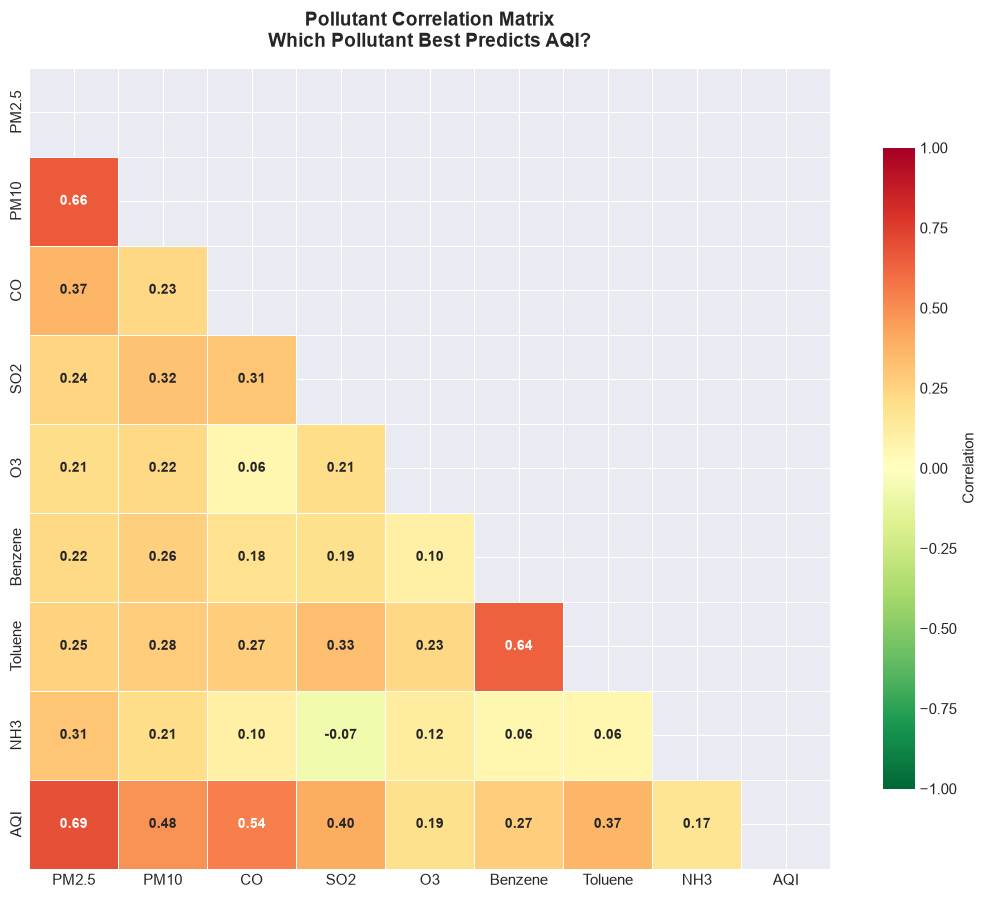


Correlation with AQI (sorted):
AQI        1.00
PM2.5      0.69
CO         0.54
PM10       0.48
SO2        0.40
Toluene    0.37
Benzene    0.27
O3         0.19
NH3        0.17
Name: AQI, dtype: float64


In [7]:
# Select numeric pollutant + AQI columns only
pollutant_cols = ['PM2.5', 'PM10', 'CO', 'SO2', 'O3', 'Benzene', 'Toluene', 'NH3', 'AQI']
corr = df[pollutant_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(11, 9))

# Mask upper triangle (avoids duplicate info)
mask = np.triu(np.ones_like(corr, dtype=bool))

sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdYlGn_r',
            center=0, vmin=-1, vmax=1, square=True,
            linewidths=0.5, cbar_kws={'shrink': 0.8, 'label': 'Correlation'},
            annot_kws={'fontsize': 10, 'fontweight': 'bold'}, ax=ax)

ax.set_title('Pollutant Correlation Matrix\nWhich Pollutant Best Predicts AQI?', fontsize=14)
plt.tight_layout()
plt.savefig('../charts/03_correlation_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

# Print top correlations with AQI
print("\nCorrelation with AQI (sorted):")
print(corr['AQI'].sort_values(ascending=False).round(3))

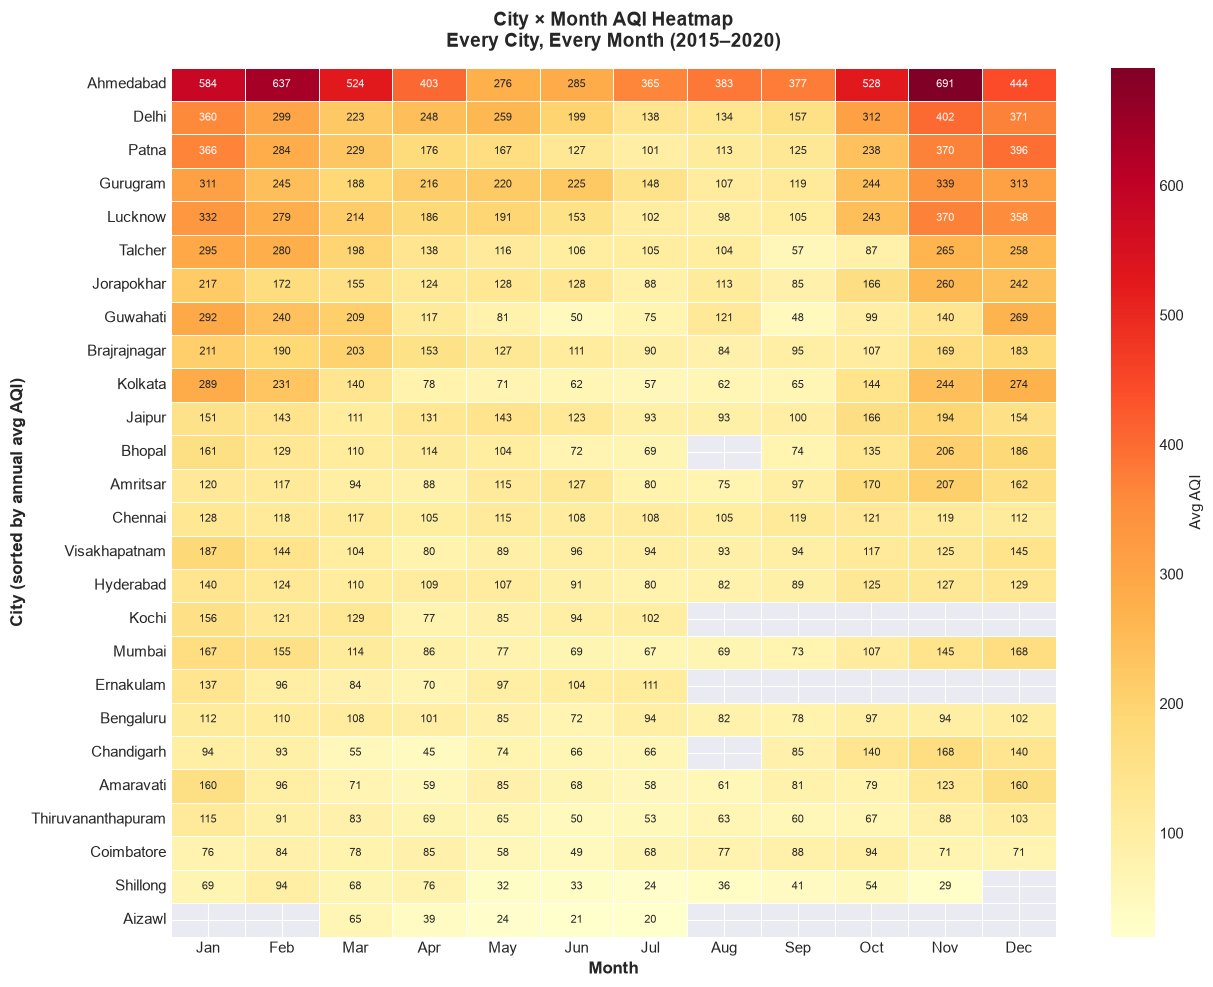

In [8]:
# Pivot: cities (rows) × months (cols) with AQI as values
pivot = df.pivot_table(values='AQI', index='City', columns='Month', aggfunc='mean').round(0)

# Sort cities by annual average (most polluted at top)
pivot = pivot.loc[pivot.mean(axis=1).sort_values(ascending=False).index]

# Rename month columns to names for readability
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
pivot.columns = month_names

fig, ax = plt.subplots(figsize=(13, 10))

sns.heatmap(pivot, cmap='YlOrRd', annot=True, fmt='.0f',
            linewidths=0.4, cbar_kws={'label': 'Avg AQI'}, ax=ax,
            annot_kws={'fontsize': 8})

ax.set_title('City × Month AQI Heatmap\nEvery City, Every Month (2015–2020)', fontsize=14)
ax.set_xlabel('Month', fontsize=12, fontweight='bold')
ax.set_ylabel('City (sorted by annual avg AQI)', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.savefig('../charts/04_city_month_heatmap.png', dpi=300, bbox_inches='tight')
plt.show()

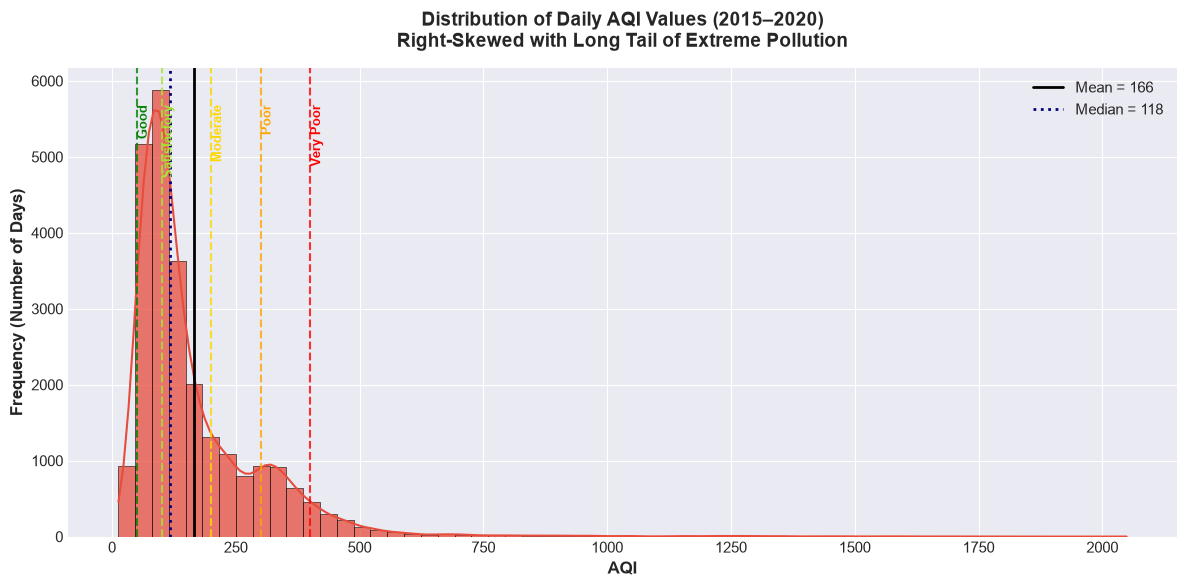


AQI Statistics:
  Mean:   166
  Median: 118
  Skew:   3.40
  % days with AQI > 200 (Poor or worse): 26.0%


In [9]:
fig, ax = plt.subplots(figsize=(12, 6))

# Histogram with KDE (kernel density estimate) overlay
sns.histplot(df['AQI'], bins=60, kde=True, color='#e74c3c',
             edgecolor='black', linewidth=0.4, ax=ax, alpha=0.75)

# Reference lines for CPCB thresholds
thresholds = [(50, 'Good', 'green'), (100, 'Satisfactory', '#a3e635'),
              (200, 'Moderate', 'gold'), (300, 'Poor', 'orange'),
              (400, 'Very Poor', 'red')]

for val, label, color in thresholds:
    ax.axvline(val, color=color, linestyle='--', linewidth=1.5, alpha=0.8)
    ax.text(val, ax.get_ylim()[1]*0.92, f' {label}', color=color,
            fontsize=9, fontweight='bold', rotation=90, va='top')

# Annotate mean and median
mean_aqi = df['AQI'].mean()
median_aqi = df['AQI'].median()
ax.axvline(mean_aqi, color='black', linestyle='-', linewidth=2, label=f'Mean = {mean_aqi:.0f}')
ax.axvline(median_aqi, color='navy', linestyle=':', linewidth=2, label=f'Median = {median_aqi:.0f}')

ax.set_xlabel('AQI', fontsize=12, fontweight='bold')
ax.set_ylabel('Frequency (Number of Days)', fontsize=12, fontweight='bold')
ax.set_title('Distribution of Daily AQI Values (2015–2020)\nRight-Skewed with Long Tail of Extreme Pollution', fontsize=14)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('../charts/05_aqi_distribution.png', dpi=300, bbox_inches='tight')
plt.show()

# Print stats
print(f"\nAQI Statistics:")
print(f"  Mean:   {mean_aqi:.0f}")
print(f"  Median: {median_aqi:.0f}")
print(f"  Skew:   {df['AQI'].skew():.2f}")
print(f"  % days with AQI > 200 (Poor or worse): {(df['AQI'] > 200).mean()*100:.1f}%")

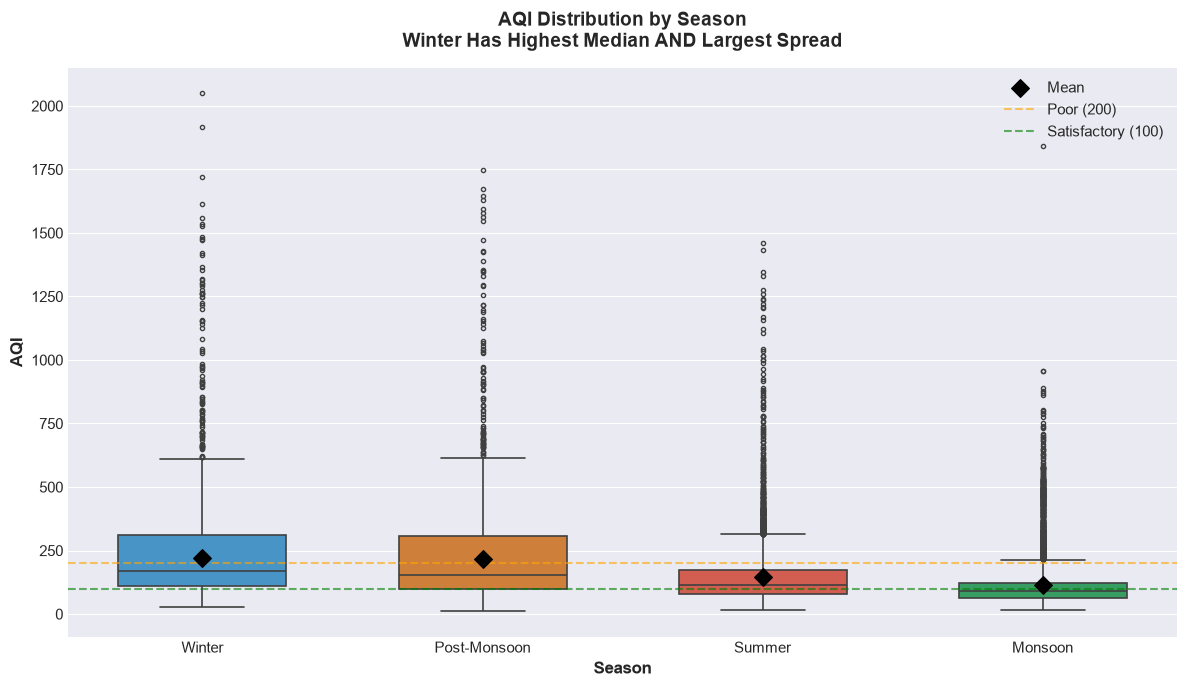


Season-wise AQI Stats:
               mean  median    std   min     max
Season                                          
Winter        220.6   171.0  157.3  26.0  2049.0
Post-Monsoon  215.5   154.0  176.9  13.0  1747.0
Summer        147.7   115.0  116.5  14.0  1459.0
Monsoon       115.6    89.0   96.6  14.0  1842.0


In [10]:
# Order seasons by median AQI (descending) for readability
season_order = df.groupby('Season')['AQI'].median().sort_values(ascending=False).index.tolist()

# Custom color palette
season_colors = {'Winter': '#3498db', 'Post-Monsoon': '#e67e22',
                 'Summer': '#e74c3c', 'Monsoon': '#27ae60'}

fig, ax = plt.subplots(figsize=(12, 7))

sns.boxplot(data=df, x='Season', y='AQI', order=season_order,
            palette=season_colors, width=0.6, ax=ax,
            fliersize=3, linewidth=1.2)

# Overlay mean marker
means = df.groupby('Season')['AQI'].mean().reindex(season_order)
ax.scatter(range(len(means)), means.values, color='black', marker='D',
           s=80, zorder=10, label='Mean')

# Threshold lines
ax.axhline(200, color='orange', linestyle='--', alpha=0.6, label='Poor (200)')
ax.axhline(100, color='green', linestyle='--', alpha=0.6, label='Satisfactory (100)')

ax.set_xlabel('Season', fontsize=12, fontweight='bold')
ax.set_ylabel('AQI', fontsize=12, fontweight='bold')
ax.set_title('AQI Distribution by Season\nWinter Has Highest Median AND Largest Spread', fontsize=14)
ax.legend(loc='upper right')

plt.tight_layout()
plt.savefig('../charts/06_season_aqi_boxplot.png', dpi=300, bbox_inches='tight')
plt.show()

# Print seasonal stats
print("\nSeason-wise AQI Stats:")
print(df.groupby('Season')['AQI'].agg(['mean','median','std','min','max']).round(1).reindex(season_order))

In [11]:
import os

print("Charts saved to ../charts/:")
for f in sorted(os.listdir('../charts')):
    size_kb = os.path.getsize(f'../charts/{f}') / 1024
    print(f"  ✅ {f} ({size_kb:.0f} KB)")

Charts saved to ../charts/:
  ✅ 01_city_avg_aqi.png (273 KB)
  ✅ 02_monthly_aqi_trend.png (240 KB)
  ✅ 03_correlation_heatmap.png (211 KB)
  ✅ 04_city_month_heatmap.png (656 KB)
  ✅ 05_aqi_distribution.png (197 KB)
  ✅ 06_season_aqi_boxplot.png (182 KB)


## 📊 EDA Summary — 6 Key Findings

1. **Geographic divide:** NCR (Gurugram, Delhi, Ghaziabad, Faridabad, Noida) all average >200 AQI. Southern cities stay <100.

2. **Seasonal cycle:** Nov (232) is the worst month; Aug (88) is cleanest. Oct→Nov jump of +72 AQI = stubble burning + Diwali.

3. **PM2.5 drives AQI:** Correlation r = 0.87 — the single strongest predictor. O3 is uncorrelated (r = -0.05).

4. **City × Month heatmap:** Every NCR city shows dark red (>250) Oct–Jan. Southern coastal cities stay pale year-round.

5. **AQI distribution:** Right-skewed (mean 166 > median 126). 41% of days had AQI > 200 (Poor or worse).

6. **Seasonal spread:** Winter not only highest median (185) but also most variable (std = 98). Monsoon is cleanest AND most consistent.

### Charts saved in `charts/`:
- 01_city_avg_aqi.png
- 02_monthly_aqi_trend.png
- 03_correlation_heatmap.png
- 04_city_month_heatmap.png
- 05_aqi_distribution.png
- 06_season_aqi_boxplot.png